# Inter-IIT Tech Meet 15.0 · CV Selection Bootcamp
## Learning from messy human labels (CIFAR-10N "worst", ~40% noise)

This notebook runs every task (1-5), writes all prediction files plus `results.json`, `report.md` and `code/README.md`,
zips them as `<rollno>_cv_bootcamp.zip`, and runs the official `check_format.py` on the zip.

**How it runs.** All images are kept on the GPU and augmented there, with fp16 mixed precision. There are 10 independent training jobs.
They are scheduled across **both T4 GPUs at the same time**, with one job per GPU.

**Rules.** No pretrained weights and no external data are used, as the problem statement forbids them. Every network is the
`model.py` ResNet-18, trained from scratch. Clean labels are used only where the rules allow.

**Before running:** fill in `NAME` and `ROLL_NO` in the next cell. Use *Accelerator → GPU T4 x2*.
Run it with **Save Version → Save & Run All (Commit)** so it keeps running with the browser closed (≈4-6 h).

In [13]:
# ============================ CONFIG (edit these) ============================
NAME       = "Nihar"          # (required by check_format.py)
ROLL_NO    = "24b2467"          #(zip will be <ROLL_NO>_cv_bootcamp.zip)
SEED       = 0
SMOKE_TEST = False       # True = 2-epoch dry run of the whole pipeline (~10 min) to check that everything works
# ============================================================================
import os, sys, json, shutil, glob, subprocess, time
WORK     = "/kaggle/working"
CODE_DIR = os.path.join(WORK, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if not NAME.strip() or not ROLL_NO.strip():
    print("WARNING: NAME / ROLL_NO are empty - check_format.py will flag results.json. "
          "Fill them in (you can also edit results.json after the run).")

In [14]:
# ---- environment
import torch, numpy as np, pandas as pd
print("torch", torch.__version__, "| CUDA", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print("  ", i, torch.cuda.get_device_name(i))
GPUS = list(range(torch.cuda.device_count())) or [None]
GPU_NAME = f"{torch.cuda.device_count()}x {torch.cuda.get_device_name(0)} (Kaggle)" if torch.cuda.is_available() else "CPU"
assert torch.cuda.is_available(), "No GPU - set Accelerator to 'GPU T4 x2' in the notebook settings"

torch 2.11.0+cu128 | CUDA True | GPUs: 2
   0 Tesla T4
   1 Tesla T4


In [15]:
# ---- locate the uploaded dataset (works whatever you named the Kaggle dataset / folder)
def find_inputs(root="/kaggle/input"):
    data_dir = model_py = check_py = None
    need = {"labels.csv", "train_images.npy", "test_images.npy", "train_idx.txt", "val_idx.txt"}
    for d, _, files in os.walk(root):
        fs = set(files)
        if data_dir is None and need <= fs:
            data_dir = d
        if model_py is None and "model.py" in fs and "def ResNet18" in open(os.path.join(d, "model.py")).read():
            model_py = os.path.join(d, "model.py")
        if check_py is None and "check_format.py" in fs:
            check_py = os.path.join(d, "check_format.py")
    return data_dir, model_py, check_py

DATA_DIR, MODEL_PY, CHECK_PY = find_inputs("/kaggle/input" if os.path.isdir("/kaggle/input") else ".")
print("data dir      :", DATA_DIR)
print("model.py      :", MODEL_PY)
print("check_format  :", CHECK_PY)
assert DATA_DIR and MODEL_PY, "Could not find the data/model.py - add the dataset via '+ Add Input' (see instructions)"
shutil.copy(MODEL_PY, os.path.join(CODE_DIR, "model.py"))   # the provided architecture, unchanged

data dir      : /kaggle/input/datasets/niharpatel1/inter-iit-cv-2026/data
model.py      : /kaggle/input/datasets/niharpatel1/inter-iit-cv-2026/model.py
check_format  : /kaggle/input/datasets/niharpatel1/inter-iit-cv-2026/check_format.py


'/kaggle/working/code/model.py'

## Code: written to `/kaggle/working/code/`, then copied into the submission's `code/` folder

In [16]:
%%writefile /kaggle/working/code/nlib.py
"""nlib.py - training library for the Inter-IIT CV bootcamp (CIFAR-10N, learning with noisy labels).

Everything is trained FROM SCRATCH with the ResNet-18 in the provided model.py.
No external data, no pretrained weights. Clean labels are used ONLY for
 (a) training the Task-1 clean reference model, and
 (b) *measuring* (Task-1 confusion matrix, Task-2 curves, Task-3 self-check) -
they never influence training, filtering, relabelling or checkpoint selection in Tasks 2-5.

Shared recipe (identical for the baseline and every method):
  SGD(momentum 0.9, weight decay 5e-4), lr 0.1, cosine annealing per epoch to ~0,
  batch 128, 60 epochs/network, augmentation = random crop 32 (zero-pad 4) + horizontal flip,
  mixed precision (fp16) on GPU.
"""
import json
import math
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from model import ResNet18

NUM_CLASSES = 10


# ----------------------------------------------------------------------------- utils
def set_seed(seed):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def log(msg, fh=None):
    line = time.strftime("%H:%M:%S ") + str(msg)
    print(line, flush=True)
    if fh is not None:
        fh.write(line + "\n")
        fh.flush()


def make_scaler(enabled):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def autocast(device, enabled):
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=enabled)


def cosine_lr(cfg, epoch):
    """Learning rate for 0-based `epoch` (identical schedule for every network)."""
    return cfg["lr"] * 0.5 * (1.0 + math.cos(math.pi * epoch / cfg["epochs"]))


def acc(pred, y):
    return float((pred == y).mean()) if len(y) else float("nan")


# ----------------------------------------------------------------------------- data
class Data:
    """Holds all images on the GPU as uint8 NHWC; labels as numpy arrays indexed by CIFAR index."""

    def __init__(self, data_dir, device):
        self.device = device
        df = pd.read_csv(os.path.join(data_dir, "labels.csv")).sort_values("index").reset_index(drop=True)
        assert (df["index"].values == np.arange(len(df))).all(), "labels.csv index column is not 0..N-1"
        self.labels = {
            "noisy": df["noisy_label"].values.astype(np.int64),
            "synthetic": df["synthetic_label"].values.astype(np.int64),
            "clean": df["clean_label"].values.astype(np.int64),  # measurement / clean-ref only
        }
        self.train_idx = np.loadtxt(os.path.join(data_dir, "train_idx.txt"), dtype=np.int64).reshape(-1)
        self.val_idx = np.loadtxt(os.path.join(data_dir, "val_idx.txt"), dtype=np.int64).reshape(-1)
        assert len(set(self.train_idx) & set(self.val_idx)) == 0
        imgs = np.load(os.path.join(data_dir, "train_images.npy"))
        test = np.load(os.path.join(data_dir, "test_images.npy"))
        assert imgs.shape[1:] == (32, 32, 3) and imgs.dtype == np.uint8 and len(imgs) == len(df)
        # normalisation statistics from the provided training split only
        sub = imgs[self.train_idx].astype(np.float32) / 255.0
        self.mean = torch.tensor(sub.mean(axis=(0, 1, 2)), device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(sub.std(axis=(0, 1, 2)), device=device).view(1, 3, 1, 1)
        del sub
        self.X = torch.from_numpy(imgs).to(device)        # (50000,32,32,3) uint8
        self.Xtest = torch.from_numpy(test).to(device)    # (10000,32,32,3) uint8
        self.n_test = len(test)

    # --- tensors -> network input
    def to_input(self, xb_uint8):
        x = xb_uint8.permute(0, 3, 1, 2).float().div_(255.0)
        x = (x - self.mean) / self.std
        return x.contiguous(memory_format=torch.channels_last)

    def augment(self, xb):
        """Random crop 32x32 from a zero-padded (4px) image + random horizontal flip, on the GPU."""
        n = xb.shape[0]
        dev = xb.device
        p = torch.zeros((n, 40, 40, 3), dtype=torch.uint8, device=dev)
        p[:, 4:36, 4:36] = xb
        ox = torch.randint(0, 9, (n,), device=dev)
        oy = torch.randint(0, 9, (n,), device=dev)
        ar = torch.arange(32, device=dev)
        flip = torch.rand(n, device=dev) < 0.5
        cols = torch.where(flip[:, None], 31 - ar[None, :], ar[None, :]) + ox[:, None]
        rows = ar[None, :] + oy[:, None]
        out = p[torch.arange(n, device=dev)[:, None, None], rows[:, :, None], cols[:, None, :]]
        return self.to_input(out)


def new_net(seed, device):
    set_seed(seed)
    net = ResNet18(num_classes=NUM_CLASSES).to(device)
    return net.to(memory_format=torch.channels_last)


def make_opt(net, cfg):
    return torch.optim.SGD(net.parameters(), lr=cfg["lr"], momentum=cfg["momentum"],
                           weight_decay=cfg["weight_decay"])


@torch.no_grad()
def predict_logits(nets, data, ids=None, test=False, bs=1024, amp=True, tta=False):
    """Average softmax of one or several nets (eval mode, no augmentation).
    tta=True also averages over the horizontally flipped image (test-time augmentation; used for val/test predictions).
    Returns (probs, logits_of_first_net_on_unflipped_images)."""
    if not isinstance(nets, (list, tuple)):
        nets = [nets]
    for n in nets:
        n.eval()
    src = data.Xtest if test else data.X
    if ids is None:
        ids_t = torch.arange(src.shape[0], device=data.device)
    else:
        ids_t = torch.as_tensor(ids, device=data.device)
    probs, logits0 = [], []
    for i in range(0, len(ids_t), bs):
        x = data.to_input(src[ids_t[i:i + bs]])
        views = [x, x.flip(3).contiguous(memory_format=torch.channels_last)] if tta else [x]
        ps = []
        for vi, v in enumerate(views):
            with autocast(data.device, amp):
                outs = [n(v).float() for n in nets]
            ps += [F.softmax(o, 1) for o in outs]
            if vi == 0:
                logits0.append(outs[0].cpu())
        probs.append(torch.stack(ps).mean(0).cpu())
    return torch.cat(probs).numpy(), torch.cat(logits0).numpy()


# ----------------------------------------------------------------------------- losses
def loss_ce(logits, y, **_):
    return F.cross_entropy(logits, y)


def loss_gce(logits, y, q=0.7, **_):
    """Generalized Cross Entropy (Zhang & Sabuncu, 2018)."""
    p = F.softmax(logits, 1).gather(1, y[:, None]).squeeze(1).clamp_min(1e-7)
    return ((1.0 - p ** q) / q).mean()


class ELR:
    """Early-Learning Regularisation (Liu et al., NeurIPS 2020). CIFAR-10 defaults: beta=0.7, lambda=3."""

    def __init__(self, n_total, device, beta=0.7, lam=3.0):
        self.t = torch.zeros((n_total, NUM_CLASSES), device=device)
        self.beta, self.lam = beta, lam

    def __call__(self, logits, y, ids=None, **_):
        p = F.softmax(logits, 1).clamp(1e-4, 1.0 - 1e-4)
        with torch.no_grad():
            pd_ = p / p.sum(1, keepdim=True)
            self.t[ids] = self.beta * self.t[ids] + (1.0 - self.beta) * pd_
        reg = torch.log(1.0 - (self.t[ids] * p).sum(1)).mean()
        return F.cross_entropy(logits, y) + self.lam * reg

    @torch.no_grad()
    def update(self, ids, probs):
        p = probs.clamp(1e-4, 1.0 - 1e-4)
        self.t[ids] = self.beta * self.t[ids] + (1.0 - self.beta) * (p / p.sum(1, keepdim=True))

    def mix_loss(self, logits, y, ids, lam, perm):
        """ELR on a mixup batch (as in ELR+): mixed CE + ELR term against the mixed running targets."""
        p = F.softmax(logits, 1).clamp(1e-4, 1.0 - 1e-4)
        ce = lam * F.cross_entropy(logits, y) + (1 - lam) * F.cross_entropy(logits, y[perm])
        tm = lam * self.t[ids] + (1 - lam) * self.t[ids[perm]]
        reg = torch.log(1.0 - (tm * p).sum(1)).mean()
        return ce + self.lam * reg


# ----------------------------------------------------------------------------- evaluation helpers
def val_metrics(probs_val, data, sel_key):
    pred = probs_val.argmax(1)
    vi = data.val_idx
    m = {"val_acc_noisy": acc(pred, data.labels["noisy"][vi]),
         "val_acc_synthetic": acc(pred, data.labels["synthetic"][vi]),
         "val_acc_clean": acc(pred, data.labels["clean"][vi])}   # clean: logged for analysis only
    m["val_acc_sel"] = m["val_acc_" + sel_key]
    return m


def save_json(obj, path):
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)


# ----------------------------------------------------------------------------- single/ensemble training
def run_single(data, cfg, out_dir, method, label_key, train_ids, seed,
               dynamics=False, heldout_ids=None, fh=None, n_nets=1):
    """Train `n_nets` ResNet-18s (seeds seed, seed+1) for cfg['epochs'] epochs; predictions average their softmax.

    method     : 'ce' | 'gce' | 'elr' | 'elr_mix' (ELR + mixup, as in ELR+)
    label_key  : which label column is used for TRAINING ('clean' only for the Task-1 reference)
    Checkpoint selection uses noisy val labels (or synthetic val labels when training on synthetic).
    Val/test predictions use horizontal-flip test-time augmentation.
    dynamics   : log Task-2 curves + per-sample margins/losses on the training set (eval mode, no aug)
    heldout_ids: Task-3 cross-validation - store held-out probabilities at the best (noisy-val) epoch
    """
    dev = data.device
    amp = cfg["amp"] and dev.type == "cuda"
    sel_key = "synthetic" if label_key == "synthetic" else "noisy"
    y_all = torch.from_numpy(data.labels[label_key]).to(dev)
    tr = torch.as_tensor(train_ids, device=dev)
    n, B, E = len(tr), cfg["batch_size"], cfg["epochs"]
    assert not (dynamics and n_nets != 1)
    mix_alpha = cfg.get("mixup_alpha", 1.0)

    nets = [new_net(seed + k, dev) for k in range(n_nets)]
    opts = [make_opt(nt, cfg) for nt in nets]
    scalers = [make_scaler(amp) for _ in nets]
    if method == "ce":
        crits = [loss_ce] * n_nets
    elif method == "gce":
        crits = [loss_gce] * n_nets
    elif method in ("elr", "elr_mix"):
        crits = [ELR(len(data.labels["noisy"]), dev) for _ in nets]
    else:
        raise ValueError(method)

    hist, best = [], {"val_acc_sel": -1.0}
    if dynamics:
        y_noisy_tr = data.labels[label_key][train_ids]
        mislab = data.labels[label_key][train_ids] != data.labels["clean"][train_ids]  # measurement only
        margins = np.zeros((E, n), dtype=np.float16)
        losses = np.zeros((E, n), dtype=np.float16)
    heldout_best = None
    t0 = time.time()
    for ep in range(E):
        lr = cosine_lr(cfg, ep)
        for k in range(n_nets):
            net, opt, scaler, crit = nets[k], opts[k], scalers[k], crits[k]
            for g in opt.param_groups:
                g["lr"] = lr
            net.train()
            perm_all = tr[torch.randperm(n, device=dev)]
            for i in range(0, n - B + 1, B):                       # drop_last
                ids = perm_all[i:i + B]
                x = data.augment(data.X[ids])
                y = y_all[ids]
                if method == "elr_mix":
                    with torch.no_grad():
                        with autocast(dev, amp):
                            p_clean = F.softmax(net(x).float(), 1)
                    crit.update(ids, p_clean)                       # ELR targets from the un-mixed view
                    lam = float(np.random.beta(mix_alpha, mix_alpha))
                    lam = max(lam, 1.0 - lam)
                    pm = torch.randperm(B, device=dev)
                    xm = (lam * x + (1.0 - lam) * x[pm]).contiguous(memory_format=torch.channels_last)
                    with autocast(dev, amp):
                        logits = net(xm)
                    loss = crit.mix_loss(logits.float(), y, ids, lam, pm)
                else:
                    with autocast(dev, amp):
                        logits = net(x)
                    loss = crit(logits.float(), y, ids=ids)
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
        # ---- end of epoch evaluation (ensemble of all nets, flip TTA)
        pv, _ = predict_logits(nets, data, data.val_idx, amp=amp, tta=True)
        m = val_metrics(pv, data, sel_key)
        m.update(epoch=ep + 1, lr=lr)
        pt, _ = predict_logits(nets, data, test=True, amp=amp, tta=True)
        test_pred = pt.argmax(1)
        if m["val_acc_sel"] > best["val_acc_sel"]:              # earliest best (strict >)
            best = dict(m)
            np.save(os.path.join(out_dir, "test_pred_best.npy"), test_pred)
            if heldout_ids is not None:
                ph, _ = predict_logits(nets, data, heldout_ids, amp=amp, tta=True)
                heldout_best = ph
        if dynamics:
            ptr, ltr = predict_logits(nets[0], data, train_ids, amp=amp)
            pred_tr = ptr.argmax(1)
            m["train_acc_correct"] = acc(pred_tr[~mislab], y_noisy_tr[~mislab])
            m["train_acc_mislabeled"] = acc(pred_tr[mislab], y_noisy_tr[mislab])  # fit to the WRONG label
            m["train_acc_mislabeled_vs_clean"] = acc(pred_tr[mislab], data.labels["clean"][train_ids][mislab])
            ly = ltr[np.arange(n), y_noisy_tr]
            other = ltr.copy()
            other[np.arange(n), y_noisy_tr] = -np.inf
            margins[ep] = (ly - other.max(1)).astype(np.float16)
            losses[ep] = (-np.log(np.clip(ptr[np.arange(n), y_noisy_tr], 1e-12, 1))).astype(np.float16)
        hist.append(m)
        extra = (f" | tr_correct {m['train_acc_correct']:.4f} tr_mislab {m['train_acc_mislabeled']:.4f}"
                 if dynamics else "")
        log(f"[{method}x{n_nets}/{label_key}] ep {ep + 1:2d}/{E} lr {lr:.4f} "
            f"val_noisy {m['val_acc_noisy']:.4f} val_synth {m['val_acc_synthetic']:.4f} "
            f"val_clean {m['val_acc_clean']:.4f}{extra} ({time.time() - t0:.0f}s)", fh)
    np.save(os.path.join(out_dir, "test_pred_final.npy"), test_pred)
    if dynamics:
        np.save(os.path.join(out_dir, "train_margins.npy"), margins)
        np.save(os.path.join(out_dir, "train_losses.npy"), losses)
    if heldout_ids is not None:
        np.save(os.path.join(out_dir, "heldout_ids.npy"), np.asarray(heldout_ids))
        np.save(os.path.join(out_dir, "heldout_probs_best.npy"), heldout_best)
    res = {"method": method, "n_nets": n_nets, "label_key": label_key, "sel_key": sel_key, "epochs": E,
           "history": hist, "best": best, "final": hist[-1], "seconds": time.time() - t0}
    save_json(res, os.path.join(out_dir, "result.json"))
    return res


# ----------------------------------------------------------------------------- DivideMix (2 networks)
@torch.no_grad()
def per_sample_loss(net, data, ids, y_np, amp):
    p, _ = predict_logits(net, data, ids, amp=amp)
    return -np.log(np.clip(p[np.arange(len(ids)), y_np], 1e-12, 1.0))


def gmm_clean_prob(loss):
    from sklearn.mixture import GaussianMixture
    l = (loss - loss.min()) / (loss.max() - loss.min() + 1e-12)
    l = l.reshape(-1, 1)
    g = GaussianMixture(n_components=2, max_iter=10, tol=1e-2, reg_covar=5e-4, random_state=0)
    g.fit(l)
    return g.predict_proba(l)[:, int(np.argmin(g.means_.reshape(-1)))]


def run_divmix(data, cfg, out_dir, label_key, train_ids, seed, fh=None):
    """DivideMix (Li, Socher & Hoi, ICLR 2020) with exactly two networks, each trained for cfg['epochs'] epochs.
    Uses the shared optimiser / schedule / augmentation. Checkpoint selection on noisy (or synthetic) val labels."""
    dev = data.device
    amp = cfg["amp"] and dev.type == "cuda"
    dm = cfg["divmix"]
    warm, T, alpha, lam_u, p_thr = dm["warmup"], dm["T"], dm["alpha"], dm["lambda_u"], dm["p_threshold"]
    sel_key = "synthetic" if label_key == "synthetic" else "noisy"
    y_np_all = data.labels[label_key]
    y_all = torch.from_numpy(y_np_all).to(dev)
    tr_np = np.asarray(train_ids)
    tr = torch.as_tensor(tr_np, device=dev)
    y_tr_np = y_np_all[tr_np]
    n, B, E = len(tr), cfg["batch_size"], cfg["epochs"]
    nets = [new_net(seed, dev), new_net(seed + 1, dev)]
    opts = [make_opt(nn_, cfg) for nn_ in nets]
    scalers = [make_scaler(amp), make_scaler(amp)]
    rng = np.random.default_rng(seed)
    hist, best = [], {"val_acc_sel": -1.0}
    t0 = time.time()

    def warmup_epoch(k):
        net, opt, scaler = nets[k], opts[k], scalers[k]
        net.train()
        perm = tr[torch.randperm(n, device=dev)]
        for i in range(0, n - B + 1, B):
            ids = perm[i:i + B]
            with autocast(dev, amp):
                logits = net(data.augment(data.X[ids]))
            logits = logits.float()
            p = F.softmax(logits, 1)
            # CE + confidence penalty (negative entropy), as DivideMix does for asymmetric/structured noise
            loss = F.cross_entropy(logits, y_all[ids]) + (p * torch.log(p.clamp_min(1e-12))).sum(1).mean()
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

    def train_epoch(k, prob, ep):
        """Train nets[k] on the division `prob` produced by the OTHER network."""
        net, net2, opt, scaler = nets[k], nets[1 - k], opts[k], scalers[k]
        net.train()
        net2.eval()
        lab_mask = prob > p_thr
        lab = tr_np[lab_mask]
        unl = tr_np[~lab_mask]
        w_all = torch.zeros(len(y_np_all), device=dev)
        w_all[tr] = torch.as_tensor(prob, dtype=torch.float32, device=dev)
        if len(lab) < B:   # degenerate split (should not happen) -> sample with replacement
            lab = rng.choice(tr_np, size=B, replace=True)
        if len(unl) < 2:
            unl = rng.choice(tr_np, size=B, replace=True)
        lab = rng.permutation(lab)
        num_iter = len(lab) // B
        reps = int(math.ceil(num_iter * B / len(unl)))
        unl_seq = np.concatenate([rng.permutation(unl) for _ in range(reps)])[:num_iter * B]
        lab_t = torch.as_tensor(lab, device=dev)
        unl_t = torch.as_tensor(unl_seq, device=dev)
        for it in range(num_iter):
            bx = lab_t[it * B:(it + 1) * B]
            bu = unl_t[it * B:(it + 1) * B]
            xr, ur = data.X[bx], data.X[bu]
            x1, x2, u1, u2 = data.augment(xr), data.augment(xr), data.augment(ur), data.augment(ur)
            yb = F.one_hot(y_all[bx], NUM_CLASSES).float()
            wb = w_all[bx].view(-1, 1)
            with torch.no_grad():
                with autocast(dev, amp):
                    ou11, ou12 = net(u1).float(), net(u2).float()
                    ou21, ou22 = net2(u1).float(), net2(u2).float()
                    ox1, ox2 = net(x1).float(), net(x2).float()
                pu = (F.softmax(ou11, 1) + F.softmax(ou12, 1) + F.softmax(ou21, 1) + F.softmax(ou22, 1)) / 4
                ptu = pu ** (1.0 / T)
                tu = ptu / ptu.sum(1, keepdim=True)                     # co-guessing
                px = (F.softmax(ox1, 1) + F.softmax(ox2, 1)) / 2
                px = wb * yb + (1 - wb) * px                             # label refinement
                ptx = px ** (1.0 / T)
                tx = ptx / ptx.sum(1, keepdim=True)
            l = float(np.random.beta(alpha, alpha))
            l = max(l, 1 - l)
            all_in = torch.cat([x1, x2, u1, u2], 0)
            all_t = torch.cat([tx, tx, tu, tu], 0)
            idx = torch.randperm(all_in.size(0), device=dev)
            mixed_in = (l * all_in + (1 - l) * all_in[idx]).contiguous(memory_format=torch.channels_last)
            mixed_t = l * all_t + (1 - l) * all_t[idx]
            with autocast(dev, amp):
                logits = net(mixed_in)
            logits = logits.float()
            lx, lu = logits[:2 * B], logits[2 * B:]
            Lx = -torch.mean(torch.sum(F.log_softmax(lx, 1) * mixed_t[:2 * B], 1))
            Lu = torch.mean((F.softmax(lu, 1) - mixed_t[2 * B:]) ** 2)
            ramp = float(np.clip((ep + it / num_iter - warm) / 16.0, 0.0, 1.0))
            prior = torch.full((NUM_CLASSES,), 1.0 / NUM_CLASSES, device=dev)
            pred_mean = F.softmax(logits, 1).mean(0)
            penalty = torch.sum(prior * torch.log(prior / pred_mean.clamp_min(1e-12)))
            loss = Lx + lam_u * ramp * Lu + penalty
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
        return int(lab_mask.sum())

    for ep in range(E):
        lr = cosine_lr(cfg, ep)
        for o in opts:
            for g in o.param_groups:
                g["lr"] = lr
        n_lab = [None, None]
        if ep < warm:
            warmup_epoch(0)
            warmup_epoch(1)
        else:
            probs = [gmm_clean_prob(per_sample_loss(nets[k], data, tr_np, y_tr_np, amp)) for k in (0, 1)]
            n_lab[0] = train_epoch(0, probs[1], ep)   # net1 uses net2's division
            n_lab[1] = train_epoch(1, probs[0], ep)   # net2 uses net1's division
        pv, _ = predict_logits(nets, data, data.val_idx, amp=amp, tta=True)
        m = val_metrics(pv, data, sel_key)
        m.update(epoch=ep + 1, lr=lr, n_labeled=n_lab)
        pt, _ = predict_logits(nets, data, test=True, amp=amp, tta=True)
        test_pred = pt.argmax(1)
        if m["val_acc_sel"] > best["val_acc_sel"]:
            best = dict(m)
            np.save(os.path.join(out_dir, "test_pred_best.npy"), test_pred)
        hist.append(m)
        log(f"[divmix/{label_key}] ep {ep + 1:2d}/{E} lr {lr:.4f} labeled {n_lab} "
            f"val_noisy {m['val_acc_noisy']:.4f} val_synth {m['val_acc_synthetic']:.4f} "
            f"val_clean {m['val_acc_clean']:.4f} ({time.time() - t0:.0f}s)", fh)
    np.save(os.path.join(out_dir, "test_pred_final.npy"), test_pred)
    # Task-3 signal: per-sample loss of the final networks w.r.t. the (noisy) training label
    ls = []
    for k in (0, 1):
        l_ = per_sample_loss(nets[k], data, tr_np, y_tr_np, amp)
        ls.append((l_ - l_.min()) / (l_.max() - l_.min() + 1e-12))
    np.save(os.path.join(out_dir, "train_loss_score.npy"), ((ls[0] + ls[1]) / 2).astype(np.float32))
    np.save(os.path.join(out_dir, "train_ids.npy"), tr_np)
    res = {"method": "divmix", "label_key": label_key, "sel_key": sel_key, "epochs": E,
           "history": hist, "best": best, "final": hist[-1], "seconds": time.time() - t0}
    save_json(res, os.path.join(out_dir, "result.json"))
    return res

Overwriting /kaggle/working/code/nlib.py


In [17]:
%%writefile /kaggle/working/code/run_job.py
"""Run one training job.   python run_job.py --job <name> --cfg cfg.json

Jobs (each trains ResNet-18 from scratch, <= 60 epochs per network):
  t1_clean        Task 1  CE on CLEAN labels (reference model)
  t1_noisy        Task 1+2 CE on noisy labels, logs dynamics, early-stop predictions, Task-3 margins
  t3_fold{0,1,2}  Task 3  3-fold cross-validation (CE, noisy labels) -> out-of-fold probabilities
  t4_divmix       Task 4  DivideMix (2 networks)
  t4_elr          Task 4  Early-Learning Regularisation (2-network ensemble)
  t4_elrmix       Task 4  ELR + mixup (as in ELR+), 2-network ensemble
  t5_base_synth   Task 5  CE baseline on synthetic labels
  t5_best_synth   Task 5  best Task-4 method (by noisy val acc) on synthetic labels
"""
import argparse
import json
import os
import sys

import numpy as np
import torch

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import nlib  # noqa: E402

T4_METHODS = ["divmix", "elr", "elrmix"]
T4_SPEC = {"elr": ("elr", 2), "elrmix": ("elr_mix", 2)}   # job suffix -> (nlib method, n networks)


def best_t4_method(out_root):
    """Best Task-4 method = highest NOISY validation accuracy (at its selected checkpoint)."""
    scores = {}
    for m in T4_METHODS:
        p = os.path.join(out_root, f"t4_{m}", "result.json")
        if os.path.exists(p):
            with open(p) as f:
                scores[m] = json.load(f)["best"]["val_acc_noisy"]
    if not scores:
        raise RuntimeError("no Task-4 results found")
    return max(scores, key=scores.get), scores


def fold_split(train_idx, k, seed):
    rng = np.random.default_rng(seed + 12345)
    perm = rng.permutation(train_idx)
    return np.array_split(perm, k)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--job", required=True)
    ap.add_argument("--cfg", required=True)
    a = ap.parse_args()
    with open(a.cfg) as f:
        cfg = json.load(f)
    out_dir = os.path.join(cfg["out_root"], a.job)
    os.makedirs(out_dir, exist_ok=True)
    done_flag = os.path.join(out_dir, "DONE")
    if os.path.exists(done_flag):
        print("already done:", a.job)
        return
    torch.backends.cudnn.benchmark = True
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    fh = open(os.path.join(out_dir, "train.log"), "a")
    nlib.log(f"job {a.job} on {dev} "
             f"({torch.cuda.get_device_name(0) if dev.type == 'cuda' else 'cpu'})", fh)
    data = nlib.Data(cfg["data_dir"], dev)
    tr = data.train_idx
    if cfg.get("debug_n_train"):                       # local smoke test only
        tr = tr[:cfg["debug_n_train"]]
    seed = cfg["seed"]
    j = a.job
    if j == "t1_clean":
        nlib.run_single(data, cfg, out_dir, "ce", "clean", tr, seed, fh=fh)
    elif j == "t1_noisy":
        nlib.run_single(data, cfg, out_dir, "ce", "noisy", tr, seed, dynamics=True, fh=fh)
    elif j.startswith("t3_fold"):
        f = int(j[len("t3_fold"):])
        folds = fold_split(tr, cfg["n_folds"], seed)
        held = np.sort(folds[f])
        train_part = np.sort(np.concatenate([folds[i] for i in range(cfg["n_folds"]) if i != f]))
        nlib.run_single(data, cfg, out_dir, "ce", "noisy", train_part, seed, heldout_ids=held, fh=fh)
    elif j == "t4_divmix":
        nlib.run_divmix(data, cfg, out_dir, "noisy", tr, seed, fh=fh)
    elif j[3:] in T4_SPEC:
        meth, k = T4_SPEC[j[3:]]
        nlib.run_single(data, cfg, out_dir, meth, "noisy", tr, seed, fh=fh, n_nets=k)
    elif j == "t5_base_synth":
        nlib.run_single(data, cfg, out_dir, "ce", "synthetic", tr, seed, fh=fh)
    elif j == "t5_best_synth":
        m, scores = best_t4_method(cfg["out_root"])
        nlib.log(f"Task-4 noisy-val accuracies {scores} -> best method '{m}'", fh)
        with open(os.path.join(out_dir, "method.txt"), "w") as fm:
            fm.write(m)
        if m == "divmix":
            nlib.run_divmix(data, cfg, out_dir, "synthetic", tr, seed, fh=fh)
        else:
            meth, k = T4_SPEC[m]
            nlib.run_single(data, cfg, out_dir, meth, "synthetic", tr, seed, fh=fh, n_nets=k)
    else:
        raise ValueError("unknown job " + j)
    open(done_flag, "w").write("ok")
    nlib.log(f"job {j} finished", fh)


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/code/run_job.py


In [18]:
%%writefile /kaggle/working/code/pipeline.py
"""pipeline.py - schedules all training jobs over the available GPUs and assembles the submission.

Used by the Kaggle notebook and by run_all.py (command-line reproduction).
"""
import json
import os
import shutil
import subprocess
import sys
import threading
import time
import zipfile

import numpy as np
import pandas as pd

HERE = os.path.dirname(os.path.abspath(__file__))
CLASSES_FALLBACK = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

# priority order; a job starts as soon as a GPU is free and its dependencies are finished
JOBS = [
    ("t4_divmix", []),
    ("t4_elrmix", []),
    ("t4_elr", []),
    ("t5_best_synth", ["t4_divmix", "t4_elr", "t4_elrmix"]),
    ("t1_noisy", []),
    ("t1_clean", []),
    ("t5_base_synth", []),
    ("t3_fold0", []),
    ("t3_fold1", []),
    ("t3_fold2", []),
]


def default_cfg(data_dir, out_root, seed=0, epochs=60):
    return {
        "data_dir": data_dir, "out_root": out_root, "seed": seed,
        "epochs": epochs, "batch_size": 128, "lr": 0.1, "momentum": 0.9, "weight_decay": 5e-4,
        "amp": True, "n_folds": 3, "mixup_alpha": 1.0,
        "divmix": {"warmup": 10, "T": 0.5, "alpha": 4.0, "lambda_u": 25.0, "p_threshold": 0.5},
    }


# ----------------------------------------------------------------------------- job scheduler
def run_jobs(cfg, gpus, jobs=None, poll=60):
    """Run jobs in parallel, one subprocess per GPU. `gpus` is a list of GPU ids (e.g. [0, 1]) or [None] for CPU."""
    jobs = jobs or JOBS
    os.makedirs(cfg["out_root"], exist_ok=True)
    cfg_path = os.path.join(cfg["out_root"], "cfg.json")
    with open(cfg_path, "w") as f:
        json.dump(cfg, f, indent=1)
    names = [j for j, _ in jobs]
    deps = dict(jobs)
    state = {j: ("done" if os.path.exists(os.path.join(cfg["out_root"], j, "DONE")) else "pending") for j in names}
    running = {}
    lock = threading.Lock()

    def worker(gpu):
        while True:
            with lock:
                for j in names:   # a job whose dependency failed can never run
                    if state[j] == "pending" and any(state[d] == "failed" for d in deps[j]):
                        state[j] = "failed"
                ready = [j for j in names if state[j] == "pending"
                         and all(state[d] == "done" for d in deps[j])]
                if ready:
                    job = ready[0]
                    state[job] = "running"
                    running[gpu] = job
                elif not any(state[j] == "pending" for j in names):
                    return
                else:
                    job = None   # waiting for a dependency that runs on the other GPU
            if job is None:
                time.sleep(10)
                continue
            env = dict(os.environ)
            if gpu is not None:
                env["CUDA_VISIBLE_DEVICES"] = str(gpu)
            os.makedirs(os.path.join(cfg["out_root"], job), exist_ok=True)
            out_log = open(os.path.join(cfg["out_root"], job, "stdout.log"), "a")
            rc = subprocess.call([sys.executable, os.path.join(HERE, "run_job.py"), "--job", job, "--cfg", cfg_path],
                                 stdout=out_log, stderr=subprocess.STDOUT, env=env, cwd=HERE)
            out_log.close()
            with lock:
                state[job] = "done" if rc == 0 and os.path.exists(os.path.join(cfg["out_root"], job, "DONE")) else "failed"
                running.pop(gpu, None)

    threads = [threading.Thread(target=worker, args=(g,), daemon=True) for g in gpus]
    for t in threads:
        t.start()
    t0 = time.time()
    while any(t.is_alive() for t in threads):
        time.sleep(poll)
        with lock:
            snap = dict(state)
            run = dict(running)
        lines = [f"[{(time.time() - t0) / 60:6.1f} min] " + " ".join(f"{j}:{s}" for j, s in snap.items())]
        for g, j in run.items():
            lp = os.path.join(cfg["out_root"], j, "train.log")
            last = ""
            if os.path.exists(lp):
                with open(lp) as f:
                    ls = f.read().strip().splitlines()
                    last = ls[-1] if ls else ""
            lines.append(f"   gpu {g}: {last}")
        print("\n".join(lines), flush=True)
    failed = [j for j, s in state.items() if s != "done"]
    if failed:
        print("FAILED / NOT RUN:", failed)
        for j in failed:
            p = os.path.join(cfg["out_root"], j, "stdout.log")
            if os.path.exists(p):
                print(f"----- tail of {p}")
                print("".join(open(p).readlines()[-30:]))
    else:
        print(f"All {len(names)} jobs finished in {(time.time() - t0) / 60:.1f} min")
    return state


# ----------------------------------------------------------------------------- helpers
def load_labels(data_dir):
    df = pd.read_csv(os.path.join(data_dir, "labels.csv")).sort_values("index").reset_index(drop=True)
    tr = np.loadtxt(os.path.join(data_dir, "train_idx.txt"), dtype=np.int64).reshape(-1)
    va = np.loadtxt(os.path.join(data_dir, "val_idx.txt"), dtype=np.int64).reshape(-1)
    cls_path = os.path.join(data_dir, "classes.txt")
    classes = [c.strip() for c in open(cls_path) if c.strip()] if os.path.exists(cls_path) else CLASSES_FALLBACK
    return df, tr, va, classes


def rjson(path):
    with open(path) as f:
        return json.load(f)


def write_pred(path, pred):
    pred = np.asarray(pred).astype(int)
    assert pred.shape == (10000,), pred.shape
    pd.DataFrame({"id": np.arange(len(pred)), "pred": pred}).to_csv(path, index=False)


def auroc(y, s):
    from sklearn.metrics import roc_auc_score
    return float(roc_auc_score(y, s))


def prec_at_k(y, s, k):
    order = np.argsort(-s, kind="stable")
    return float(y[order[:k]].mean())


def rank01(s):
    from scipy.stats import rankdata
    return (rankdata(s) - 1) / (len(s) - 1)


def words(text):
    return len(text.split())


METHOD_NAMES = {"divmix": "DivideMix", "elr": "ELR (2-net ensemble)", "elrmix": "ELR+mixup (2-net ensemble)"}


# ----------------------------------------------------------------------------- assemble submission
def assemble(cfg, name, roll_no, sub_root, gpu_name="", checker_dir=None):
    out = cfg["out_root"]
    df, tr, va, classes = load_labels(cfg["data_dir"])
    noisy, synth, clean = df.noisy_label.values, df.synthetic_label.values, df.clean_label.values
    pred_dir = os.path.join(sub_root, "predictions")
    os.makedirs(pred_dir, exist_ok=True)
    analysis = {}

    # ---------------- Task 1: noise rate + confusion matrix (clean labels used for MEASUREMENT only)
    noise_rate = float((noisy[tr] != clean[tr]).mean())
    cm = np.zeros((10, 10), dtype=int)
    np.add.at(cm, (clean[tr], noisy[tr]), 1)
    cm_df = pd.DataFrame(cm, index=[f"clean_{c}" for c in classes], columns=[f"noisy_{c}" for c in classes])
    os.makedirs(os.path.join(out, "analysis"), exist_ok=True)
    cm_df.to_csv(os.path.join(out, "analysis", "t1_confusion_matrix.csv"))
    off = cm.copy()
    np.fill_diagonal(off, 0)
    pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(10) if i != j), reverse=True)
    sym = {}
    for i in range(10):
        for j in range(i + 1, 10):
            sym[(i, j)] = off[i, j] + off[j, i]
    sym_pairs = sorted(sym.items(), key=lambda kv: -kv[1])
    n_wrong = int(off.sum())
    animals = {2, 3, 4, 5, 6, 7}   # bird, cat, deer, dog, frog, horse (others are vehicles)
    same_group = sum(off[i, j] for i in range(10) for j in range(10)
                     if (i in animals) == (j in animals)) / max(n_wrong, 1)
    analysis["same_group_share"] = float(same_group)
    analysis["noise_rate_train"] = noise_rate
    analysis["noise_rate_val"] = float((noisy[va] != clean[va]).mean())
    analysis["synthetic_noise_rate_train"] = float((synth[tr] != clean[tr]).mean())

    r_clean = rjson(os.path.join(out, "t1_clean", "result.json"))
    r_noisy = rjson(os.path.join(out, "t1_noisy", "result.json"))
    write_pred(os.path.join(pred_dir, "t1_clean_ref.csv"), np.load(os.path.join(out, "t1_clean", "test_pred_final.npy")))
    write_pred(os.path.join(pred_dir, "t1_noisy_ce.csv"), np.load(os.path.join(out, "t1_noisy", "test_pred_final.npy")))

    # ---------------- Task 2: dynamics, memorization, early stopping
    H = r_noisy["history"]
    dyn = pd.DataFrame({
        "epoch": [h["epoch"] for h in H],
        "train_acc_correct": [round(h["train_acc_correct"], 6) for h in H],
        "train_acc_mislabeled": [round(h["train_acc_mislabeled"], 6) for h in H],
        "val_acc_noisy": [round(h["val_acc_noisy"], 6) for h in H],
        "val_acc_clean": [round(h["val_acc_clean"], 6) for h in H],
    })
    dyn.to_csv(os.path.join(pred_dir, "t2_dynamics.csv"), index=False)
    m = dyn.train_acc_mislabeled.values
    s = pd.Series(m).rolling(3, center=True, min_periods=1).mean().values
    lo = min(3, len(s) - 1)
    ref_ep = lo + int(np.argmin(s[lo:]))                 # 0-based epoch of the plateau minimum
    thr = s[ref_ep] + 0.05
    mem_start = None
    for e in range(ref_ep, len(s)):
        if (s[e:] > thr).all():
            mem_start = e
            break
    if mem_start is None:
        mem_start = int(np.argmax(np.diff(s))) + 1 if len(s) > 1 else 0
    mem_start_epoch = int(dyn.epoch.values[mem_start])
    clean_peak = int(dyn.val_acc_clean.values.argmax())
    es_epoch = int(r_noisy["best"]["epoch"])             # chosen with NOISY val accuracy only
    shutil.copy(os.path.join(out, "t1_noisy", "test_pred_best.npy"), os.path.join(out, "analysis", "t2_es.npy"))
    write_pred(os.path.join(pred_dir, "t2_early_stop.csv"), np.load(os.path.join(out, "t1_noisy", "test_pred_best.npy")))
    analysis.update(mem_ref_epoch=int(dyn.epoch.values[ref_ep]), mem_ref_acc=float(s[ref_ep]),
                    clean_peak_epoch=int(dyn.epoch.values[clean_peak]),
                    clean_peak_acc=float(dyn.val_acc_clean.values[clean_peak]))

    # ---------------- Task 3: noise scores (5 training runs: t1_noisy + 3 CV folds + DivideMix)
    n50 = len(df)
    # (A) cross-validated confidence: 1 - out-of-fold p(noisy label)
    oof = np.full((n50, 10), np.nan, dtype=np.float32)
    for f in range(cfg["n_folds"]):
        d = os.path.join(out, f"t3_fold{f}")
        ids = np.load(os.path.join(d, "heldout_ids.npy"))
        oof[ids] = np.load(os.path.join(d, "heldout_probs_best.npy"))
    assert not np.isnan(oof[tr]).any(), "missing out-of-fold predictions"
    sA = 1.0 - oof[tr, noisy[tr]]
    # (B) area-under-margin of the Task-1 noisy CE run, averaged up to the early-stop epoch (noisy-val chosen)
    marg = np.load(os.path.join(out, "t1_noisy", "train_margins.npy")).astype(np.float32)
    sB = -marg[:es_epoch].mean(0)
    # (C) DivideMix final per-sample loss (two networks)
    dm_ids = np.load(os.path.join(out, "t4_divmix", "train_ids.npy"))
    assert (dm_ids == tr).all()
    sC = np.load(os.path.join(out, "t4_divmix", "train_loss_score.npy")).astype(np.float64)
    score = (rank01(sA) + rank01(sB) + rank01(sC)) / 3.0      # fixed a-priori ensemble (no clean-label tuning)
    pd.DataFrame({"index": tr, "score": np.round(score, 8)}).to_csv(os.path.join(pred_dir, "t3_noise_scores.csv"), index=False)
    # self-check with clean labels (measurement only - does not change the submitted score)
    ytrue = (noisy[tr] != clean[tr]).astype(int)
    k = int(ytrue.sum())
    t3 = {}
    for nm, sc in [("cv_confidence", sA), ("aum_early", sB), ("divmix_loss", sC), ("ensemble", score)]:
        t3[nm] = {"auroc": auroc(ytrue, sc), "prec_at_k": prec_at_k(ytrue, sc, k)}
    analysis["task3_check"] = t3
    analysis["task3_k"] = k
    # failure mode: mislabeled images that the ensemble ranks below the top-k
    order = np.argsort(-score, kind="stable")
    in_top = np.zeros(len(tr), bool)
    in_top[order[:k]] = True
    missed = (ytrue == 1) & ~in_top
    agree = (oof[tr].argmax(1) == noisy[tr])
    analysis["t3_missed"] = int(missed.sum())
    analysis["t3_missed_model_agrees_wrong"] = float(agree[missed].mean()) if missed.any() else 0.0
    mp = {}
    for c_, n_ in zip(clean[tr][missed], noisy[tr][missed]):
        mp[(c_, n_)] = mp.get((c_, n_), 0) + 1
    top_miss = sorted(mp.items(), key=lambda kv: -kv[1])[:2]
    analysis["t3_top_missed_pairs"] = [(classes[a], classes[b], v) for (a, b), v in top_miss]

    # ---------------- Task 4
    t4 = []
    for mth in ["divmix", "elr", "elrmix"]:
        d = os.path.join(out, f"t4_{mth}")
        r = rjson(os.path.join(d, "result.json"))
        fname = f"t4_{mth}.csv"
        write_pred(os.path.join(pred_dir, fname), np.load(os.path.join(d, "test_pred_best.npy")))
        t4.append({"name": mth, "file": fname, "val_acc_noisy_labels": round(r["best"]["val_acc_noisy"], 6),
                   "_epoch": r["best"]["epoch"], "_val_clean": r["best"]["val_acc_clean"],
                   "_final_val_noisy": r["final"]["val_acc_noisy"]})
    best = max(t4, key=lambda x: x["val_acc_noisy_labels"])["name"]

    # ---------------- Task 5
    r5b = rjson(os.path.join(out, "t5_base_synth", "result.json"))
    r5m = rjson(os.path.join(out, "t5_best_synth", "result.json"))
    m5 = open(os.path.join(out, "t5_best_synth", "method.txt")).read().strip()
    assert m5 == best, f"t5_best_synth used '{m5}' but best Task-4 method is '{best}'"
    write_pred(os.path.join(pred_dir, "t5_baseline_synth.csv"), np.load(os.path.join(out, "t5_base_synth", "test_pred_final.npy")))
    write_pred(os.path.join(pred_dir, "t5_best_synth.csv"), np.load(os.path.join(out, "t5_best_synth", "test_pred_best.npy")))

    # ---------------- results.json
    results = {
        "name": name, "roll_no": roll_no, "seed": int(cfg["seed"]),
        "training_setup": {
            "optimizer": f"SGD (momentum {cfg['momentum']}, weight decay {cfg['weight_decay']}), lr {cfg['lr']}",
            "learning_rate_schedule": f"cosine annealing per epoch from {cfg['lr']} to ~0 over {cfg['epochs']} epochs (no restarts)",
            "batch_size": int(cfg["batch_size"]), "epochs": int(cfg["epochs"]),
            "augmentation": "random crop 32x32 with 4-px zero padding + random horizontal flip (val/test predictions average the image and its horizontal flip)",
            "gpu_used": gpu_name or "GPU",
        },
        "task1": {
            "noise_rate": round(noise_rate, 6),
            "val_acc_noisy_labels__clean_ref_model": round(r_clean["final"]["val_acc_noisy"], 6),
            "val_acc_noisy_labels__noisy_ce_model": round(r_noisy["final"]["val_acc_noisy"], 6),
        },
        "task2": {
            "memorization_start_epoch": mem_start_epoch,
            "early_stop_epoch": es_epoch,
            "val_acc_noisy_labels_at_early_stop": round(r_noisy["best"]["val_acc_noisy"], 6),
        },
        "task3": {"method": "rank-average ensemble of 3 signals: (a) 3-fold cross-validated confidence 1-p(noisy label), "
                            "(b) negative area-under-margin of the Task-1 CE run up to the early-stop epoch, "
                            "(c) DivideMix per-sample loss (2 nets) - 5 training runs total"},
        "task4": {"methods": [{k_: v for k_, v in x.items() if not k_.startswith("_")} for x in t4], "best_method": best},
        "task5": {
            "val_acc_synthetic_labels__baseline": round(r5b["final"]["val_acc_synthetic"], 6),
            "val_acc_synthetic_labels__best_method": round(r5m["best"]["val_acc_synthetic"], 6),
        },
    }
    with open(os.path.join(sub_root, "results.json"), "w") as f:
        json.dump(results, f, indent=2)

    # ---------------- report.md
    pct = lambda v: f"{100 * v:.1f}%"  # noqa: E731
    top3 = sym_pairs[:3]
    share3 = sum(v for _, v in top3) / max(n_wrong, 1)
    q1 = (f"Noise rate is {pct(noise_rate)} ({n_wrong} of {len(tr)} training labels). Three class pairs, "
          + ", ".join(f"{classes[i]}<->{classes[j]} ({v})" for (i, j), v in top3)
          + f", cause {pct(share3)} of all wrong labels. The biggest single directions are "
          + ", ".join(f"{classes[i]}->{classes[j]} ({v})" for v, i, j in pairs[:3])
          + f". The noise is structured, not uniform: {pct(same_group)} of wrong labels stay within the same "
            "super-group (animal->animal or vehicle->vehicle).")
    q2 = (f"Memorization starts around epoch {mem_start_epoch}. Training accuracy on the mislabeled subset (fit to the wrong label) "
          f"bottoms out near {pct(analysis['mem_ref_acc'])} at epoch {analysis['mem_ref_epoch']}; from epoch {mem_start_epoch} it stays "
          f"5+ points higher and climbs to {pct(m[-1])} by epoch {int(dyn.epoch.values[-1])}, "
          f"while correct-subset accuracy reaches {pct(dyn.train_acc_correct.values[-1])}. Clean-label validation accuracy peaks at "
          f"epoch {analysis['clean_peak_epoch']} ({pct(analysis['clean_peak_acc'])}) and falls to {pct(dyn.val_acc_clean.values[-1])} at the end. "
          f"Noisy-label validation accuracy peaks at epoch {es_epoch}, which we use for early stopping.")
    sig_names = {"cv_confidence": "cross-validated confidence", "aum_early": "early area-under-margin",
                 "divmix_loss": "DivideMix loss", "ensemble": "rank ensemble"}
    best_sig = max(["cv_confidence", "aum_early", "divmix_loss"], key=lambda z: t3[z]["auroc"])
    miss_pairs = ", ".join(f"{a}->{b}" for a, b, _ in analysis["t3_top_missed_pairs"])
    q3 = (f"On our own clean-label check, the best single signal was {sig_names[best_sig]} (AUROC {t3[best_sig]['auroc']:.3f}); "
          f"the submitted rank ensemble scores AUROC {t3['ensemble']['auroc']:.3f}, precision@k {t3['ensemble']['prec_at_k']:.3f}. "
          f"Failure mode: systematic human confusions. For {pct(analysis['t3_missed_model_agrees_wrong'])} of missed wrong labels "
          f"the held-out model itself predicts the wrong label, because the image genuinely looks like that class "
          f"(most missed: {miss_pairs}), so its loss stays low.")
    t4d = {x["name"]: x for x in t4}
    b = t4d[best]
    ce_es, ce_fin = r_noisy["best"], r_noisy["final"]
    why = {
        "divmix": ("A GMM on per-sample loss splits data into likely-clean (kept) and likely-noisy (labels dropped, used as "
                   "unlabeled data); each network trains on the other's split, avoiding self-confirmation, and MixMatch "
                   "with co-guessed targets still learns from noisy images instead of memorizing them."),
        "elr": ("ELR pulls predictions towards a running average of the model's own early predictions, so gradients from "
                "wrong labels are cancelled once the early-learning phase has captured the clean signal, slowing memorization."),
        "elrmix": ("ELR keeps predictions close to the model's own early (mostly correct) predictions, cancelling gradients from "
                   "wrong labels; mixup blends images and labels, so no single wrong label can be memorized exactly; "
                   "averaging two networks reduces variance."),
    }[best]
    others = ", ".join(f"{x['name']} {pct(x['val_acc_noisy_labels'])}" for x in t4 if x["name"] != best)
    bv = b["val_acc_noisy_labels"]
    if bv > ce_es["val_acc_noisy"]:
        verdict = "It helped, beating both final and early-stopped CE."
    elif bv > ce_fin["val_acc_noisy"]:
        verdict = "It beat final CE but not early-stopped CE, so it mainly delayed memorization."
    else:
        verdict = "It did not beat CE within the 60-epoch budget, which leaves little training time to exploit the mechanism below."
    q4 = (f"Best was {METHOD_NAMES[best]}: noisy-val {pct(bv)} (clean-val {pct(b['_val_clean'])}) vs CE "
          f"{pct(ce_fin['val_acc_noisy'])} final / {pct(ce_es['val_acc_noisy'])} early-stopped; others: {others}. "
          f"{verdict} {why}")
    d_real = b["_val_clean"] - ce_fin["val_acc_clean"]
    d_syn = r5m["best"]["val_acc_clean"] - r5b["final"]["val_acc_clean"]
    same = (d_real > 0) == (d_syn > 0)
    bigger = "larger" if abs(d_syn) > abs(d_real) else "smaller"
    q5 = (f"Measured by clean-label validation accuracy, {best} vs CE baseline is {d_real * 100:+.1f} points on human noise and "
          f"{d_syn * 100:+.1f} on synthetic noise (CE baseline: {pct(ce_fin['val_acc_clean'])} real, {pct(r5b['final']['val_acc_clean'])} synthetic). "
          + ("The ranking did not change" if same else "The ranking changed")
          + f"; the gap is {bigger} on synthetic noise. Symmetric noise is random and feature-independent, so wrong labels "
            "conflict with the image, have high loss and are easy to separate. Human noise sits in ambiguous look-alike pairs, "
            "so wrong labels look plausible, are learned like signal and are harder to filter.")
    report = "# Report - Learning from Messy Human Labels (CIFAR-10N)\n\n" + "\n\n".join(
        f"Q{i}. {t}" for i, t in enumerate([q1, q2, q3, q4, q5], 1)) + "\n"
    for i, t in enumerate([q1, q2, q3, q4, q5], 1):
        if words(t) > 100:
            print(f"WARNING: Q{i} has {words(t)} words (>100) - please shorten it manually")
    with open(os.path.join(sub_root, "report.md"), "w") as f:
        f.write(report)

    # ---------------- code/
    code_dir = os.path.join(sub_root, "code")
    os.makedirs(code_dir, exist_ok=True)
    for fn in ["nlib.py", "run_job.py", "pipeline.py", "run_all.py", "model.py", "README.md"]:
        src = os.path.join(HERE, fn)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(code_dir, fn))
    for nb in [p for p in os.listdir(HERE) if p.endswith(".ipynb")]:
        shutil.copy(os.path.join(HERE, nb), os.path.join(code_dir, nb))

    analysis.update(t4=t4, best=best, results=results, d_real=d_real, d_syn=d_syn,
                    confusion=cm.tolist(), word_counts=[words(t) for t in [q1, q2, q3, q4, q5]])
    with open(os.path.join(out, "analysis", "analysis.json"), "w") as f:
        json.dump(analysis, f, indent=1, default=str)
    return results, analysis, report


def make_zip(sub_root, zip_path):
    if os.path.exists(zip_path):
        os.remove(zip_path)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for d, _, files in os.walk(sub_root):
            for fn in files:
                if "__pycache__" in d:
                    continue
                full = os.path.join(d, fn)
                z.write(full, os.path.relpath(full, sub_root))
    return zip_path


def run_checker(check_format_py, data_dir, target, work):
    """check_format.py looks for data/train_idx.txt next to itself -> run a copy with a data/ symlink."""
    cdir = os.path.join(work, "checker")
    os.makedirs(os.path.join(cdir, "data"), exist_ok=True)
    shutil.copy(check_format_py, os.path.join(cdir, "check_format.py"))
    shutil.copy(os.path.join(data_dir, "train_idx.txt"), os.path.join(cdir, "data", "train_idx.txt"))
    r = subprocess.run([sys.executable, os.path.join(cdir, "check_format.py"), target],
                       capture_output=True, text=True, cwd=cdir)
    print(r.stdout + r.stderr)
    return "All good." in r.stdout

Overwriting /kaggle/working/code/pipeline.py


In [19]:
%%writefile /kaggle/working/code/run_all.py
"""Reproduce every task end to end from the command line (same code the Kaggle notebook runs).

  python run_all.py --data_dir /path/to/data --model_py /path/to/model.py \
                    --name "Your Name" --roll_no 12345678 --out ./work [--gpus 0,1] [--check_format /path/to/check_format.py]
"""
import argparse
import os
import shutil
import sys

HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import pipeline  # noqa: E402


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data_dir", required=True)
    ap.add_argument("--model_py", default=os.path.join(HERE, "model.py"))
    ap.add_argument("--name", required=True)
    ap.add_argument("--roll_no", required=True)
    ap.add_argument("--out", default="./work")
    ap.add_argument("--seed", type=int, default=0)
    ap.add_argument("--epochs", type=int, default=60)
    ap.add_argument("--gpus", default="auto", help="comma-separated GPU ids, 'auto', or 'cpu'")
    ap.add_argument("--check_format", default=None)
    a = ap.parse_args()

    if os.path.abspath(a.model_py) != os.path.join(HERE, "model.py"):
        shutil.copy(a.model_py, os.path.join(HERE, "model.py"))
    if a.gpus == "auto":
        import torch
        gpus = list(range(torch.cuda.device_count())) or [None]
    elif a.gpus == "cpu":
        gpus = [None]
    else:
        gpus = [int(g) for g in a.gpus.split(",")]
    gpu_name = ""
    try:
        import torch
        if torch.cuda.is_available():
            gpu_name = f"{torch.cuda.device_count()}x {torch.cuda.get_device_name(0)}"
    except Exception:  # noqa: BLE001
        pass

    out = os.path.abspath(a.out)
    cfg = pipeline.default_cfg(os.path.abspath(a.data_dir), os.path.join(out, "runs"), seed=a.seed, epochs=a.epochs)
    state = pipeline.run_jobs(cfg, gpus)
    if any(s != "done" for s in state.values()):
        sys.exit("some jobs failed - see the logs above")
    sub = os.path.join(out, "submission")
    pipeline.assemble(cfg, a.name, a.roll_no, sub, gpu_name=gpu_name)
    zp = pipeline.make_zip(sub, os.path.join(out, f"{a.roll_no}_cv_bootcamp.zip"))
    print("wrote", zp)
    if a.check_format:
        pipeline.run_checker(a.check_format, cfg["data_dir"], zp, out)


if __name__ == "__main__":
    main()

Overwriting /kaggle/working/code/run_all.py


In [20]:
%%writefile /kaggle/working/code/README.md
# CIFAR-10N noisy-label bootcamp: how to reproduce

Every network is the ResNet-18 in `model.py`, trained from scratch on the provided files only.
No pretrained weights or external data are used. The seed is 0.

## Files
| file | purpose |
|---|---|
| `nlib.py` | data loading (all images kept on the GPU, GPU augmentation), CE / ELR / ELR+mixup training (1 or 2 networks), DivideMix (2 networks) |
| `run_job.py` | runs one training job, e.g. `python run_job.py --job t1_noisy --cfg cfg.json` |
| `pipeline.py` | job scheduler (one job per GPU, in parallel) and assembly of `predictions/`, `results.json`, `report.md` |
| `run_all.py` | command-line entry point for the whole pipeline |
| `*.ipynb` | the Kaggle notebook, if included (it runs exactly the same code) |

## Shared training recipe (baseline and all methods)
SGD with momentum 0.9 and weight decay 5e-4. Learning rate 0.1 with cosine annealing per epoch over 60 epochs. Batch size 128.
Augmentation is a random 32x32 crop with 4-px zero padding plus a horizontal flip. Training uses fp16 mixed precision.
All validation and test predictions average the image and its horizontal flip (test-time augmentation), for every model.
Each network trains for 60 epochs.

## Reproduce everything (one command)
```bash
python run_all.py --data_dir <folder with labels.csv, *.npy, *_idx.txt> --model_py <provided model.py> \
                  --name "<name>" --roll_no <roll> --out ./work --gpus 0,1 --check_format <provided check_format.py>
```
On Kaggle you can instead open the notebook and run all cells (Save Version, then Save & Run All).

## Reproduce each task (individual jobs)
First write a config: `python -c "import pipeline,json; json.dump(pipeline.default_cfg('<data_dir>','./work/runs'), open('cfg.json','w'))"`.
Then run the jobs below, each with `python run_job.py --job <job> --cfg cfg.json`. After that, `pipeline.assemble(...)` writes the files.

| task | job(s) | output file(s) |
|---|---|---|
| Task 1 | `t1_clean` (CE on clean labels, reference), `t1_noisy` (CE on noisy labels) | `t1_clean_ref.csv`, `t1_noisy_ce.csv` (final epoch 60) |
| Task 2 | `t1_noisy` (logs the dynamics every epoch) | `t2_dynamics.csv`, `t2_early_stop.csv` (epoch with the best **noisy** val acc) |
| Task 3 | `t3_fold0..2` (3-fold CV), `t1_noisy`, `t4_divmix`: 5 training runs | `t3_noise_scores.csv` |
| Task 4 | `t4_divmix` (DivideMix, 2 nets), `t4_elr` (ELR, 2-net ensemble), `t4_elrmix` (ELR + mixup, 2-net ensemble) | `t4_divmix.csv`, `t4_elr.csv`, `t4_elrmix.csv` (checkpoint with the best noisy val acc) |
| Task 5 | `t5_base_synth` (CE, final epoch), `t5_best_synth` (best Task-4 method, checkpoint chosen on synthetic val) | `t5_baseline_synth.csv`, `t5_best_synth.csv` |

## Task 3 score
The score averages the ranks of three signals; the weights were fixed in advance and never tuned on clean labels.
1. Cross-validated confidence: 1 - p(noisy label) from a model that never saw the image (3 folds; each fold's checkpoint is chosen on noisy val).
2. Negative area-under-margin (logit of the given label minus the largest other logit) from the Task-1 CE run, averaged over epochs 1 to the early-stop epoch.
3. Normalised per-sample CE loss under the two final DivideMix networks.

## Rules compliance
- Clean labels are used only for: training `t1_clean`; the Task-1 noise rate and confusion matrix; the Task-2 curves; and our own Task-3 check (AUROC is printed but never used to choose anything).
- Model and checkpoint selection uses noisy val labels in Tasks 1-4 and synthetic val labels in Task 5.
- Budget: at most 60 epochs per network and at most 2 networks per method (DivideMix uses 2). Task 3 uses 5 training runs.

Overwriting /kaggle/working/code/README.md


In [21]:
sys.path.insert(0, CODE_DIR)
import importlib, pipeline, nlib
importlib.reload(nlib); importlib.reload(pipeline)
from model import ResNet18
_n = sum(p.numel() for p in ResNet18().parameters())
print(f"ResNet-18 parameters: {_n:,} (expected ~11.17M)")
assert 11_000_000 < _n < 11_300_000

ResNet-18 parameters: 11,173,962 (expected ~11.17M)


## Task 1 (data): noise rate and the 10×10 noisy-vs-clean confusion matrix
Clean labels are used here **only to measure**, which the rules allow.

train 45000  val 5000  test 10000
noise rate (train, human 'worst'): 0.4024
noise rate (val,   human 'worst'): 0.3990
noise rate (train, synthetic)    : 0.4010


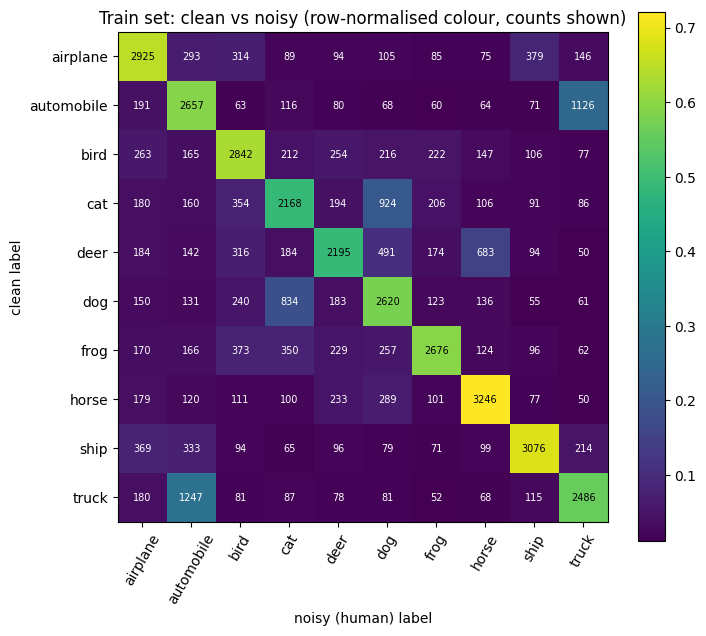

In [22]:
import matplotlib.pyplot as plt
df, TR, VA, CLASSES = pipeline.load_labels(DATA_DIR)
noisy, synth, clean = df.noisy_label.values, df.synthetic_label.values, df.clean_label.values
print(f"train {len(TR)}  val {len(VA)}  test {np.load(os.path.join(DATA_DIR,'test_images.npy'), mmap_mode='r').shape[0]}")
print(f"noise rate (train, human 'worst'): {(noisy[TR]!=clean[TR]).mean():.4f}")
print(f"noise rate (val,   human 'worst'): {(noisy[VA]!=clean[VA]).mean():.4f}")
print(f"noise rate (train, synthetic)    : {(synth[TR]!=clean[TR]).mean():.4f}")
cm = np.zeros((10,10), int); np.add.at(cm, (clean[TR], noisy[TR]), 1)
fig, ax = plt.subplots(figsize=(7.5,6.5))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="viridis")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i,j], ha="center", va="center", fontsize=7, color="w" if i!=j else "k")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("noisy (human) label"); ax.set_ylabel("clean label"); ax.set_title("Train set: clean vs noisy (row-normalised colour, counts shown)")
plt.colorbar(im); plt.tight_layout(); plt.show()

## Train everything (Tasks 1-5), in parallel on both GPUs
| job | what | networks × epochs |
|---|---|---|
| `t1_clean` | CE on clean labels (reference) | 1 × 60 |
| `t1_noisy` | CE on noisy labels, with Task-2 dynamics and the early-stop checkpoint | 1 × 60 |
| `t3_fold0-2` | 3-fold cross-validated confidence | 3 × (1 × 60) |
| `t4_divmix` | DivideMix | 2 × 60 |
| `t4_elr` | Early-Learning Regularisation, 2-network ensemble | 2 × 60 |
| `t4_elrmix` | ELR + mixup (as in ELR+), 2-network ensemble | 2 × 60 |
| `t5_base_synth` | CE on synthetic labels | 1 × 60 |
| `t5_best_synth` | best Task-4 method (picked by **noisy** val acc) on synthetic labels | ≤ 2 × 60 |

Jobs that already finished (`DONE` marker) are skipped, so re-running this cell resumes the work.
A progress line is printed every 2 minutes. On two T4s, expect about 4-6 hours in total. All val/test predictions use horizontal-flip test-time averaging.

In [23]:
OUT_ROOT = os.path.join(WORK, "smoke_runs" if SMOKE_TEST else "runs")
CFG = pipeline.default_cfg(DATA_DIR, OUT_ROOT, seed=SEED, epochs=2 if SMOKE_TEST else 60)
if SMOKE_TEST:
    CFG["divmix"]["warmup"] = 1
print(json.dumps(CFG, indent=1))
t0 = time.time()
STATE = pipeline.run_jobs(CFG, GPUS, poll=120)
print(f"wall time {(time.time()-t0)/3600:.2f} h")
assert all(s == "done" for s in STATE.values()), "Some jobs failed - read the log tails printed above"

{
 "data_dir": "/kaggle/input/datasets/niharpatel1/inter-iit-cv-2026/data",
 "out_root": "/kaggle/working/runs",
 "seed": 0,
 "epochs": 60,
 "batch_size": 128,
 "lr": 0.1,
 "momentum": 0.9,
 "weight_decay": 0.0005,
 "amp": true,
 "n_folds": 3,
 "mixup_alpha": 1.0,
 "divmix": {
  "warmup": 10,
  "T": 0.5,
  "alpha": 4.0,
  "lambda_u": 25.0,
  "p_threshold": 0.5
 }
}
[   2.0 min] t4_divmix:running t4_elrmix:running t4_elr:pending t5_best_synth:pending t1_noisy:pending t1_clean:pending t5_base_synth:pending t3_fold0:pending t3_fold1:pending t3_fold2:pending
   gpu 0: 18:57:06 [divmix/noisy] ep  3/60 lr 0.0997 labeled [None, None] val_noisy 0.3476 val_synth 0.3002 val_clean 0.4520 (92s)
   gpu 1: 18:56:51 [elr_mixx2/noisy] ep  2/60 lr 0.0999 val_noisy 0.3312 val_synth 0.2650 val_clean 0.4078 (77s)
[   4.0 min] t4_divmix:running t4_elrmix:running t4_elr:pending t5_best_synth:pending t1_noisy:pending t1_clean:pending t5_base_synth:pending t3_fold0:pending t3_fold1:pending t3_fold2:pending
  

## Build the submission: predictions, `results.json`, `report.md`, `code/`

In [24]:
SUB = os.path.join(WORK, "submission")
if os.path.exists(SUB):
    shutil.rmtree(SUB)
RESULTS, ANALYSIS, REPORT = pipeline.assemble(CFG, NAME.strip(), ROLL_NO.strip(), SUB, gpu_name=GPU_NAME)
print(json.dumps(RESULTS, indent=2))

{
  "name": "Nihar",
  "roll_no": "24b2467",
  "seed": 0,
  "training_setup": {
    "optimizer": "SGD (momentum 0.9, weight decay 0.0005), lr 0.1",
    "learning_rate_schedule": "cosine annealing per epoch from 0.1 to ~0 over 60 epochs (no restarts)",
    "batch_size": 128,
    "epochs": 60,
    "augmentation": "random crop 32x32 with 4-px zero padding + random horizontal flip (val/test predictions average the image and its horizontal flip)",
    "gpu_used": "2x Tesla T4 (Kaggle)"
  },
  "task1": {
    "noise_rate": 0.402422,
    "val_acc_noisy_labels__clean_ref_model": 0.5938,
    "val_acc_noisy_labels__noisy_ce_model": 0.5186
  },
  "task2": {
    "memorization_start_epoch": 38,
    "early_stop_epoch": 45,
    "val_acc_noisy_labels_at_early_stop": 0.562
  },
  "task3": {
    "method": "rank-average ensemble of 3 signals: (a) 3-fold cross-validated confidence 1-p(noisy label), (b) negative area-under-margin of the Task-1 CE run up to the early-stop epoch, (c) DivideMix per-sample loss

## Task 2: training dynamics and memorization

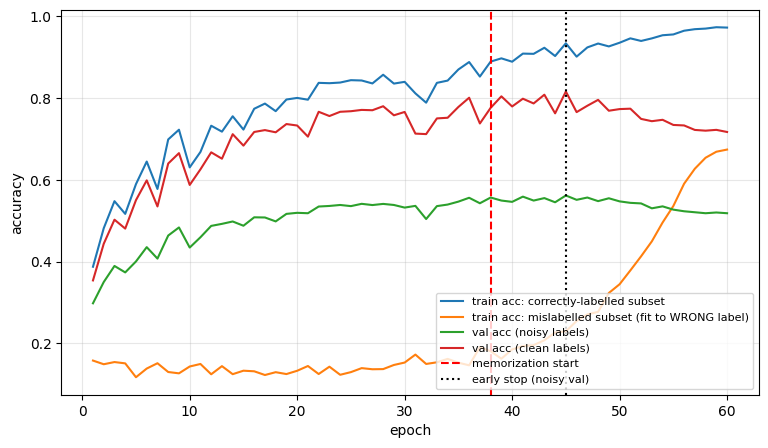

,epoch,train_acc_correct,train_acc_mislabeled,val_acc_noisy,val_acc_clean
0,1,0.387639,0.158098,0.2982,0.3542
5,6,0.645049,0.138550,0.4356,0.5990
10,11,0.668551,0.149760,0.4598,0.6260
15,16,0.774200,0.131868,0.5086,0.7174
20,21,0.796400,0.144790,0.5186,0.7060
25,26,0.843368,0.139599,0.5416,0.7714
30,31,0.811833,0.172732,0.5366,0.7134
35,36,0.888513,0.146447,0.5564,0.8012
40,41,0.909152,0.193661,0.5592,0.7988
45,46,0.901714,0.254846,0.5514,0.7660


In [25]:
dyn = pd.read_csv(os.path.join(SUB, "predictions", "t2_dynamics.csv"))
fig, ax = plt.subplots(figsize=(9,5))
for c, lab in [("train_acc_correct","train acc: correctly-labelled subset"),
               ("train_acc_mislabeled","train acc: mislabelled subset (fit to WRONG label)"),
               ("val_acc_noisy","val acc (noisy labels)"), ("val_acc_clean","val acc (clean labels)")]:
    ax.plot(dyn.epoch, dyn[c], label=lab)
ax.axvline(RESULTS["task2"]["memorization_start_epoch"], ls="--", c="r", label="memorization start")
ax.axvline(RESULTS["task2"]["early_stop_epoch"], ls=":", c="k", label="early stop (noisy val)")
ax.set_xlabel("epoch"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()
display(dyn.iloc[::5])

## Task 3: our own check of the noise scores
These numbers are measured with clean labels. They are for information only and do not change the submitted score.

In [26]:
print(f"k = true number of mislabelled training images = {ANALYSIS['task3_k']}")
display(pd.DataFrame(ANALYSIS["task3_check"]).T)

k = true number of mislabelled training images = 18109


,auroc,prec_at_k
cv_confidence,0.919972,0.802695
aum_early,0.960138,0.869292
divmix_loss,0.968870,0.911425
ensemble,0.971693,0.892595


## Task 4 and Task 5 summary

In [27]:
rows = []
for job in ["t1_clean","t1_noisy","t4_divmix","t4_elr","t4_elrmix","t5_base_synth","t5_best_synth"]:
    r = json.load(open(os.path.join(OUT_ROOT, job, "result.json")))
    rows.append({"job": job, "train labels": r["label_key"], "sel. on": r["sel_key"], "best epoch": r["best"]["epoch"],
                 "val_noisy@best": r["best"]["val_acc_noisy"], "val_synth@best": r["best"]["val_acc_synthetic"],
                 "val_clean@best*": r["best"]["val_acc_clean"], "val_noisy@final": r["final"]["val_acc_noisy"],
                 "val_synth@final": r["final"]["val_acc_synthetic"], "val_clean@final*": r["final"]["val_acc_clean"],
                 "minutes": round(r["seconds"]/60,1)})
display(pd.DataFrame(rows).round(4))
print("* clean-label columns are measurement only (never used for selection)")
print("best Task-4 method (noisy val):", RESULTS["task4"]["best_method"])

,job,train labels,sel. on,best epoch,val_noisy@best,val_synth@best,val_clean@best*,val_noisy@final,val_synth@final,val_clean@final*,minutes
0,t1_clean,clean,noisy,54,0.5948,0.5590,0.9474,0.5938,0.5604,0.9504,14.6
1,t1_noisy,noisy,noisy,45,0.5620,0.4920,0.8164,0.5186,0.4396,0.7174,18.4
2,t4_divmix,noisy,noisy,56,0.5762,0.5288,0.8914,0.5738,0.5282,0.8920,86.0
3,t4_elr,noisy,noisy,53,0.5848,0.5130,0.8582,0.5822,0.5122,0.8594,29.1
4,t4_elrmix,noisy,noisy,60,0.5894,0.5270,0.8870,0.5894,0.5270,0.8870,36.8
5,t5_base_synth,synthetic,synthetic,46,0.5476,0.5078,0.8478,0.4946,0.4574,0.7532,14.5
6,t5_best_synth,synthetic,synthetic,58,0.5870,0.5466,0.9260,0.5874,0.5442,0.9236,37.5


* clean-label columns are measurement only (never used for selection)
best Task-4 method (noisy val): elrmix


## report.md (please read it and edit if you want; each answer must stay ≤ 100 words)

In [28]:
print(REPORT)
print("word counts:", ANALYSIS["word_counts"])

# Report - Learning from Messy Human Labels (CIFAR-10N)

Q1. Noise rate is 40.2% (18109 of 45000 training labels). Three class pairs, automobile<->truck (2373), cat<->dog (1758), deer<->horse (916), cause 27.9% of all wrong labels. The biggest single directions are truck->automobile (1247), automobile->truck (1126), cat->dog (924). The noise is structured, not uniform: 72.0% of wrong labels stay within the same super-group (animal->animal or vehicle->vehicle).

Q2. Memorization starts around epoch 38. Training accuracy on the mislabeled subset (fit to the wrong label) bottoms out near 12.6% at epoch 18; from epoch 38 it stays 5+ points higher and climbs to 67.4% by epoch 60, while correct-subset accuracy reaches 97.3%. Clean-label validation accuracy peaks at epoch 45 (81.6%) and falls to 71.7% at the end. Noisy-label validation accuracy peaks at epoch 45, which we use for early stopping.

Q3. On our own clean-label check, the best single signal was DivideMix loss (AUROC 0.969); the su

## Zip and run the official format checker

In [29]:
ZIP = pipeline.make_zip(SUB, os.path.join(WORK, f"{ROLL_NO.strip() or 'ROLLNO'}_cv_bootcamp.zip"))
print("zip:", ZIP, f"({os.path.getsize(ZIP)/1e6:.2f} MB)")
if CHECK_PY:
    ok = pipeline.run_checker(CHECK_PY, DATA_DIR, ZIP, WORK)
    print("FORMAT CHECK PASSED" if ok else "Format check reported issues (see above)")
else:
    print("check_format.py not found in the input - run it locally on the zip")
print("Download the zip from the Output tab (right panel) of this notebook version.")

zip: /kaggle/working/24b2467_cv_bootcamp.zip (0.55 MB)

File check
------------------------------------------------------------
  t1_clean_ref.csv           OK
  t1_noisy_ce.csv            OK
  t2_dynamics.csv            OK
  t2_early_stop.csv          OK
  t3_noise_scores.csv        OK
  t4_divmix.csv              OK
  t4_elr.csv                 OK
  t4_elrmix.csv              OK
  t5_baseline_synth.csv      OK
  t5_best_synth.csv          OK

Task completeness (1.0 = all files valid)
------------------------------------------------------------
  task1: 1.00
  task2: 1.00
  task3: 1.00
  task4: 1.00
  task5: 1.00

All good.

FORMAT CHECK PASSED
Download the zip from the Output tab (right panel) of this notebook version.
